In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [2]:
df=pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset.csv")

In [4]:
df.shape

(113627, 56)

In [5]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0.0,0.0,1.0,34.0,20.0,28.0,119.0,0.0,124.0,1.0
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0.0,0.0,1.0,50.0,9.0,8.0,39.0,0.0,217.0,1.0
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0.0,0.0,1.0,10.0,2.0,7.0,42.0,2.0,5.0,1.0
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1.0,1.0,1.0,3.0,27.0,15.0,22.0,1.0,31.0,1.0
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1.0,0.0,1.0,244.0,15.0,34.0,72.0,1.0,85.0,1.0


In [12]:
df.columns.tolist()

['FILENAME',
 'URL',
 'URLLength',
 'Domain',
 'DomainLength',
 'IsDomainIP',
 'TLD',
 'URLSimilarityIndex',
 'CharContinuationRate',
 'TLDLegitimateProb',
 'URLCharProb',
 'TLDLength',
 'NoOfSubDomain',
 'HasObfuscation',
 'NoOfObfuscatedChar',
 'ObfuscationRatio',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'IsHTTPS',
 'LineOfCode',
 'LargestLineLength',
 'HasTitle',
 'Title',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'HasFavicon',
 'Robots',
 'IsResponsive',
 'NoOfURLRedirect',
 'NoOfSelfRedirect',
 'HasDescription',
 'NoOfPopup',
 'NoOfiFrame',
 'HasExternalFormSubmit',
 'HasSocialNet',
 'HasSubmitButton',
 'HasHiddenFields',
 'HasPasswordField',
 'Bank',
 'Pay',
 'Crypto',
 'HasCopyrightInfo',
 'NoOfImage',
 'NoOfCSS',
 'NoOfJS',
 'NoOfSelfRef',
 'NoOfEmptyRef',
 'NoOfExternalRef',
 'label']

In [15]:
df.isnull().sum().sum()

np.int64(38)

In [17]:
df["label"].value_counts()

,count
label,
1.0,65545
0.0,48081


In [22]:
df=df.dropna(subset=["label"])
y = (df["label"] == 0).astype(int)
X = df.select_dtypes(include="number").drop(
    columns=["label"], errors="ignore"
)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
print(X.shape)
print(y.value_counts())

(113626, 50)
label
0    65545
1    48081
Name: count, dtype: int64


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 90900
Testing records: 22726


In [24]:

model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree training completed!")


Decision Tree training completed!


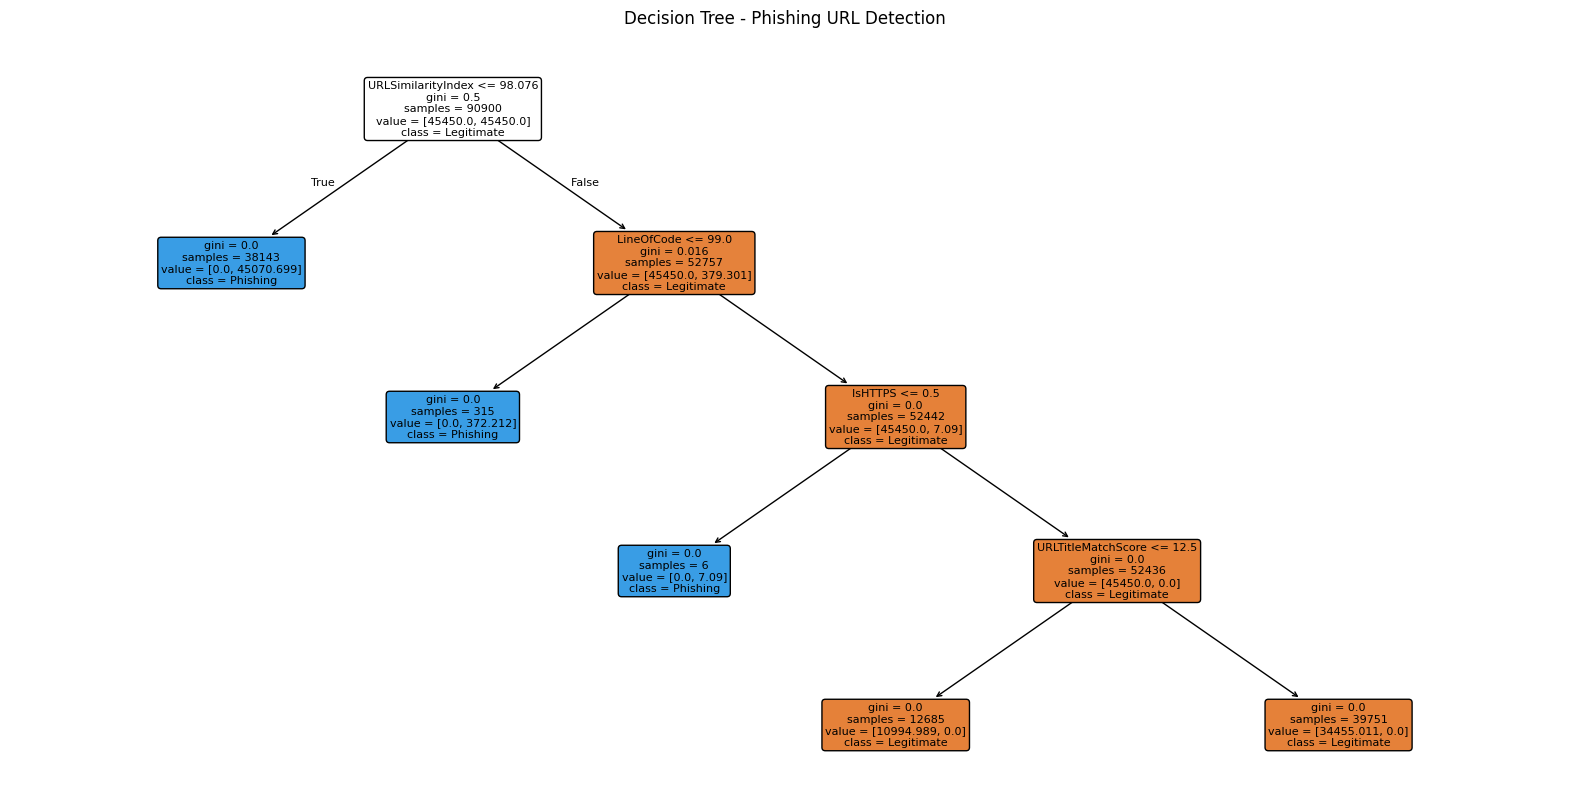

In [25]:

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Legitimate", "Phishing"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree - Phishing URL Detection")
plt.show()


In [26]:

y_pred = model.predict(X_test)

print("Actual labels:")
print(y_test.head(10).to_numpy())

print("Predicted labels:")
print(y_pred[:10])


Actual labels:
[0 0 0 0 1 0 0 0 0 1]
Predicted labels:
[0 0 0 0 1 0 0 0 0 1]


Confusion Matrix:
[[13109     0]
 [    0  9617]]


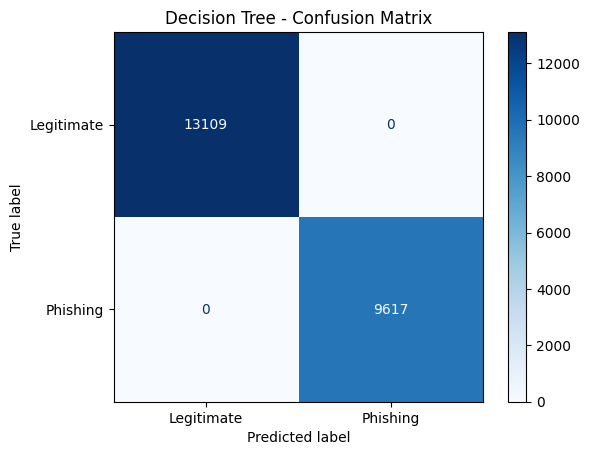

In [27]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
).plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [29]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

In [30]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)



print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"Specificity : {specificity:.4f}")


MODEL EVALUATION RESULTS
------------------------
Accuracy    : 1.0000
Precision   : 1.0000
Recall      : 1.0000
F1-score    : 1.0000
Specificity : 1.0000
